<a href="https://colab.research.google.com/github/Mojoyinola-A/Brain-Tumor-MRI-Explainability/blob/main/Brain_Tumor_MRI_Classification_and_Explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Tumor Classification Using Deep Learning

## 1. Project Overview

This project compares CNN and ResNet50 for classifying brain MRI images into three tumor types (Glioma, pituitary and meningioma).

I also use Grad-CAM to check where the model focuses and test whether small image changes affect its predictions.

## 2. Import Libraries

I import the Python libraries needed to load MRI images, prepare the data, train the models, and display results.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import scipy.io as sio

import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

## 3. Connect Google Drive

I connect Google Drive to access the MRI dataset and save my project files.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 4. Locate the Dataset

I check my Google Drive folder to find the MRI dataset used in this project.

In [ ]:
project_path = "/content/drive/MyDrive/CSCI7090"

print(os.listdir(project_path))

['Brain Tumor MRI.zip', 'Dataset', 'Models', 'Results', 'reliability_expanded.pdf', 'reliability_expanded.png', 'gradcam_full_test_comparison.pdf', 'gradcam_full_test_comparison.png', 'gradcam_full_test_results.csv', 'gradcam_representative_cases.pdf', 'gradcam_representative_cases.png', 'gradcam_representative_cases_labeled.pdf', 'gradcam_representative_cases_labeled.png', 'gradcam_additional_examples.png']


## 5. Check the Dataset Folder

I check the dataset folder to see where the MRI images and other files are stored.

In [ ]:
dataset_path = os.path.join(project_path, "Dataset")

print(os.listdir(dataset_path))

['Original', 'Extracted', 'Processed']


## 6. Check Dataset Files

I check the dataset folders to locate the MRI images and the saved data split.

In [ ]:
for folder in ["Original", "Extracted", "Processed"]:
    folder_path = os.path.join(dataset_path, folder)

    print(folder, ":", os.listdir(folder_path)[:10])

Original : []
Extracted : ['brainTumorDataPublic_1-766.zip', 'brainTumorDataPublic_1533-2298.zip', 'brainTumorDataPublic_767-1532.zip', 'brainTumorDataPublic_2299-3064.zip', 'sample_part1', 'All_MAT_Files', 'cvind.mat', 'README 2024.txt']
Processed : ['dataset_split.csv', 'dataset_split_FINAL.csv']


## **7. Check MRI Images and Data Split**

I check the MRI files and the final data split before loading the images.

In [ ]:
mri_path = os.path.join(dataset_path, "Extracted", "All_MAT_Files")
split_path = os.path.join(dataset_path, "Processed", "dataset_split_FINAL.csv")

mri_files = [f for f in os.listdir(mri_path) if f.endswith(".mat")]

print("Total MRI files:", len(mri_files))
print("Final split file exists:", os.path.exists(split_path))

split_df = pd.read_csv(split_path)
print("\nSplit columns:", split_df.columns.tolist())
print(split_df.head())

Total MRI files: 3064
Final split file exists: True

Split columns: ['file_name', 'patient_id', 'label', 'split']
  file_name patient_id  label  split
0     1.mat     100360      1  train
1     2.mat     100360      1  train
2     3.mat     100360      1  train
3     4.mat     100360      1  train
4     5.mat     100360      1  train


## **8. Check the Data Split**

I check how many images and patients are in each group. I also make sure the same patient does not appear in different groups.

In [ ]:
# Count images in each group
print("Images per split:")
print(split_df["split"].value_counts())

# Count patients in each group
print("\nPatients per split:")
print(split_df.groupby("split")["patient_id"].nunique())

# Check whether any patient appears in more than one group
patient_splits = split_df.groupby("patient_id")["split"].nunique()

print("\nPatients in multiple splits:", (patient_splits > 1).sum())

Images per split:
split
train         2177
test           462
validation     425
Name: count, dtype: int64

Patients per split:
split
test           35
train         163
validation     35
Name: patient_id, dtype: int64

Patients in multiple splits: 0


## **9. Tumor Class Distribution**

I check how many MRI images belong to each tumor class to understand the dataset.

In [ ]:
# Tumor labels in the dataset
class_names = {
    1: "Meningioma",
    2: "Glioma",
    3: "Pituitary"
}

# Count images in each class
class_counts = split_df["label"].value_counts().sort_index()

for label, count in class_counts.items():
    print(class_names[label], ":", count)

Meningioma : 708
Glioma : 1426
Pituitary : 930


## **10. View Sample MRI Images**

I display one MRI image from each tumor class to see what the original images look like before preprocessing.

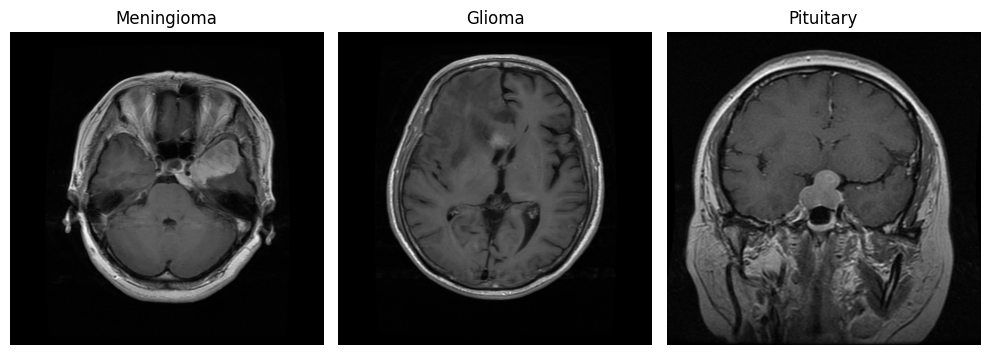

In [ ]:
import h5py

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for i, (label, name) in enumerate(class_names.items()):
    file_name = split_df[split_df["label"] == label]["file_name"].iloc[0]
    file_path = os.path.join(mri_path, file_name)

    with h5py.File(file_path, "r") as data:
        image = data["cjdata"]["image"][:]

    axes[i].imshow(image.T, cmap="gray")
    axes[i].set_title(name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## **11. Check Original Image Sizes**

I check the original MRI image sizes before resizing them for the models, to understand why resizing is needed

In [ ]:
# Check the dimensions of three sample MRI images
for file_name in mri_files[:3]:
    file_path = os.path.join(mri_path, file_name)

    with h5py.File(file_path, "r") as data:
        print(file_name, ":", data["cjdata"]["image"].shape)

2066.mat : (512, 512)
2067.mat : (512, 512)
2065.mat : (512, 512)


## **12. Image Preprocessing**

I resize the MRI images to 224 × 224 pixels and normalize their pixel values between 0 and 1 to prepare them for the models.

In [ ]:
# Load one MRI image
file_path = os.path.join(mri_path, mri_files[0])

with h5py.File(file_path, "r") as data:
    original_image = data["cjdata"]["image"][:].T

# Resize the image
resized_image = cv2.resize(
    original_image, (224, 224), interpolation=cv2.INTER_AREA
)

# Convert to float before normalization
resized_image = resized_image.astype("float32")

# Normalize pixel values between 0 and 1
normalized_image = cv2.normalize(
    resized_image, None, 0, 1, cv2.NORM_MINMAX
)

print("Original size:", original_image.shape)
print("Preprocessed size:", normalized_image.shape)
print("Pixel range:", normalized_image.min(), "to", normalized_image.max())

Original size: (512, 512)
Preprocessed size: (224, 224)
Pixel range: 0.0 to 0.99999994


## **13. Preprocessing Visualization**

I compare the original MRI image with the preprocessed image to see how resizing and normalization affect it.

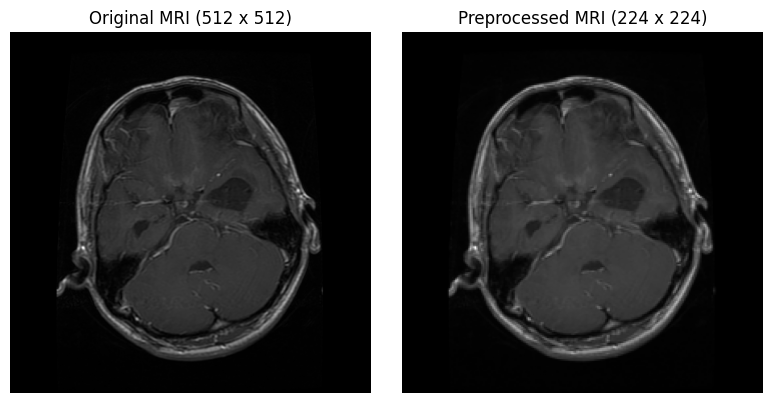

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_image, cmap="gray")
axes[0].set_title("Original MRI (512 x 512)")
axes[0].axis("off")

axes[1].imshow(normalized_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Preprocessed MRI (224 x 224)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## **14. Data Augmentation**

I use small changes in rotation, position, zoom, and contrast to help the model learn from different image variations. Augmentation is applied only to training images.

In [ ]:
# Create the augmentation layers
rotation = keras.layers.RandomRotation(0.03)
translation = keras.layers.RandomTranslation(0.03, 0.03)
zoom = keras.layers.RandomZoom(0.05, 0.05)
contrast = keras.layers.RandomContrast(0.10)

# Prepare the image for augmentation
image_input = tf.convert_to_tensor(normalized_image[None, :, :, None])

# Apply each augmentation separately
rotated = rotation(image_input, training=True)[0, :, :, 0].numpy()
translated = translation(image_input, training=True)[0, :, :, 0].numpy()
zoomed = zoom(image_input, training=True)[0, :, :, 0].numpy()
contrasted = contrast(image_input, training=True)[0, :, :, 0].numpy()

## **15. Data Augmentation Visualization**

I compare the original and preprocessed MRI images with the augmented versions to see how each transformation changes the image.

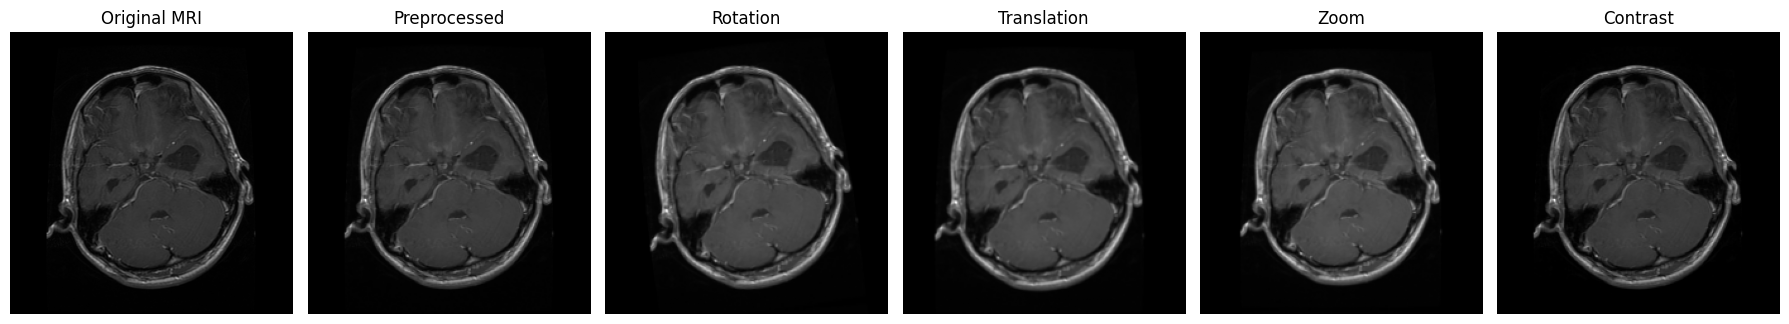

In [ ]:
# Images and their titles
images = [
    original_image,
    normalized_image,
    rotated,
    translated,
    zoomed,
    contrasted
]

titles = [
    "Original MRI",
    "Preprocessed",
    "Rotation",
    "Translation",
    "Zoom",
    "Contrast"
]

# Display all six images
fig, axes = plt.subplots(1, 6, figsize=(18, 4))

for i in range(6):
    axes[i].imshow(images[i], cmap="gray")
    axes[i].set_title(titles[i])
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## 16. Prepare MRI Images

I use the same preprocessing steps for all MRI images so they have the same size and pixel range.

In [ ]:
# Function to preprocess one MRI image
def preprocess_image(file_name):
    file_path = os.path.join(mri_path, file_name)

    with h5py.File(file_path, "r") as data:
        image = data["cjdata"]["image"][:].T

    # Resize the image
    image = cv2.resize(image, (224, 224), interpolation=cv2.INTER_AREA)

    # Normalize pixel values
    image = image.astype("float32")
    image = cv2.normalize(image, None, 0, 1, cv2.NORM_MINMAX)

    # Convert grayscale to 3 channels
    image = np.stack([image, image, image], axis=-1)

    return image

## 17. Load Training, Validation, and Test Images

I load and preprocess the MRI images using the saved patient-level split. This keeps the same patients in each group as the original experiment.

In [ ]:
# Prepare images and labels for each split
def load_split(split_name):
    rows = split_df[split_df["split"] == split_name]

    images = []
    labels = []

    for _, row in rows.iterrows():
        image = preprocess_image(row["file_name"])

        images.append(image)
        labels.append(int(row["label"]) - 1)

    return np.array(images, dtype="float32"), np.array(labels)


# Load each group separately
X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (2177, 224, 224, 3) (2177,)
Validation: (425, 224, 224, 3) (425,)
Testing: (462, 224, 224, 3) (462,)


## 18. Calculate Class Weights

I calculate class weights so the model gives more attention to tumor classes with fewer training images.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate weights using training labels only
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(weights))

print("Class weights:", class_weights)

Class weights: {0: np.float64(1.4426772697150432), 1: np.float64(0.7045307443365696), 2: np.float64(1.1268115942028984)}


## **19. Baseline CNN Model**

I use a simple CNN as my baseline model. This helps me compare a model trained from scratch with the pretrained ResNet50 model.

## **20. Build the CNN**

I build a CNN with three convolutional layers to learn features from the MRI images. The final layer predicts one of the three tumor classes.

In [ ]:
cnn_model = keras.Sequential([
    keras.layers.Input(shape=(224, 224, 3)),

    keras.layers.Conv2D(32, 3, activation="relu"),
    keras.layers.MaxPooling2D(),

    keras.layers.Conv2D(64, 3, activation="relu"),
    keras.layers.MaxPooling2D(),

    keras.layers.Conv2D(128, 3, activation="relu"),
    keras.layers.MaxPooling2D(),

    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(3, activation="softmax")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

## **21. Compile the CNN**

I use the Adam optimizer, sparse categorical cross-entropy loss, and accuracy to train and evaluate the baseline CNN.

In [ ]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully!")

CNN compiled successfully!


## **22. Set Up Training Callbacks**

I use early stopping to prevent unnecessary training when validation performance stops improving. I also save the best model based on validation loss.

In [ ]:
# Save the best CNN model
cnn_save_path = os.path.join(project_path, "Models", "cnn_baseline_final.keras")

cnn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=cnn_save_path,
        monitor="val_loss",
        save_best_only=True
    )
]

print("Training callbacks are ready!")

Training callbacks are ready!


## **23. Training Data Augmentation**

I apply small random rotations, translations, zooms, and contrast changes during training. This helps the CNN learn from different image variations.

Augmentation is applied only to training images, not validation or test images.

In [ ]:
# Data augmentation for training
data_augmentation = keras.Sequential([
    keras.layers.RandomRotation(0.03),
    keras.layers.RandomTranslation(0.03, 0.03),
    keras.layers.RandomZoom(0.05, 0.05),
    keras.layers.RandomContrast(0.10)
])

print("Data augmentation is ready!")

Data augmentation is ready!


## **24. Train the Baseline CNN**

I train the CNN for a maximum of 30 epochs using data augmentation, class weights, and early stopping. I monitor validation loss to save the best model. The epoch stopped at 20.

In [ ]:
# Apply augmentation only to training images
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))

train_dataset = train_dataset.shuffle(2177).batch(32)

train_dataset = train_dataset.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    )
)

# Train the baseline CNN
cnn_history = cnn_model.fit(
    train_dataset,
    validation_data=(X_val, y_val),
    epochs=30,
    callbacks=cnn_callbacks,
    class_weight=class_weights
)

Epoch 1/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 248s 4s/step - accuracy: 0.5292 - loss: 0.9536 - val_accuracy: 0.6447 - val_loss: 0.8054
Epoch 2/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 251s 4s/step - accuracy: 0.5930 - loss: 0.8312 - val_accuracy: 0.4400 - val_loss: 1.0545
Epoch 3/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 253s 3s/step - accuracy: 0.5737 - loss: 0.8575 - val_accuracy: 0.5435 - val_loss: 0.8465
Epoch 4/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 250s 4s/step - accuracy: 0.5985 - loss: 0.8161 - val_accuracy: 0.6047 - val_loss: 0.7733
Epoch 5/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 262s 4s/step - accuracy: 0.6008 - loss: 0.8069 - val_accuracy: 0.5976 - val_loss: 0.7689
Epoch 6/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 260s 4s/step - accuracy: 0.6206 - loss: 0.7815 - val_accuracy: 0.6424 - val_loss: 0.7269
Epoch 7/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 264s 4s/step - accuracy: 0.6256 - loss: 0.7697 - val_accuracy: 0.5812 - val_loss: 0.7651
Epoch 8/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 243s 4s/step - accuracy: 0.6031 - loss: 0.7815 - val_accuracy: 0.7106 - v

## 25. CNN Training Performance

I compare training and validation accuracy and loss to understand how the CNN learned and whether overfitting occurred.

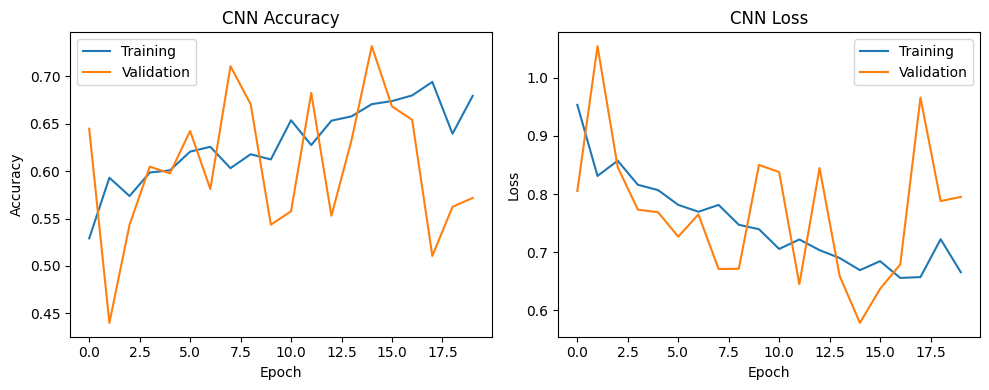

In [ ]:
plt.figure(figsize=(10, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training")
plt.plot(cnn_history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training")
plt.plot(cnn_history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 26. CNN Test Evaluation

I evaluate the best CNN model on the held-out test dataset to measure its classification performance on unseen MRI images.

In [ ]:
# Evaluate CNN on the test dataset
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test, y_test, verbose=1
)

print(f"CNN Test Accuracy: {cnn_test_accuracy * 100:.2f}%")
print(f"CNN Test Loss: {cnn_test_loss:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 983ms/step - accuracy: 0.6948 - loss: 0.5915
CNN Test Accuracy: 69.48%
CNN Test Loss: 0.5915


## 27. CNN Classification Report

I examine precision, recall, and F1-score for each tumor class to understand where the CNN performs well and where it makes mistakes.

In [ ]:
# Predict tumor classes
cnn_predictions = cnn_model.predict(X_test)

# Convert probabilities into class labels
cnn_pred_labels = np.argmax(cnn_predictions, axis=1)

# Display classification report
print(classification_report(
    y_test,
    cnn_pred_labels,
    labels=[0, 1, 2],
    target_names=["Meningioma", "Glioma", "Pituitary"]
))

15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 973ms/step
              precision    recall  f1-score   support

  Meningioma       0.45      0.33      0.38       114
      Glioma       0.67      0.71      0.69       210
   Pituitary       0.87      0.96      0.91       138

    accuracy                           0.69       462
   macro avg       0.66      0.67      0.66       462
weighted avg       0.67      0.69      0.68       462



## 28. CNN Confusion Matrix

I use a confusion matrix to identify which tumor types the CNN classifies correctly and which classes it confuses.

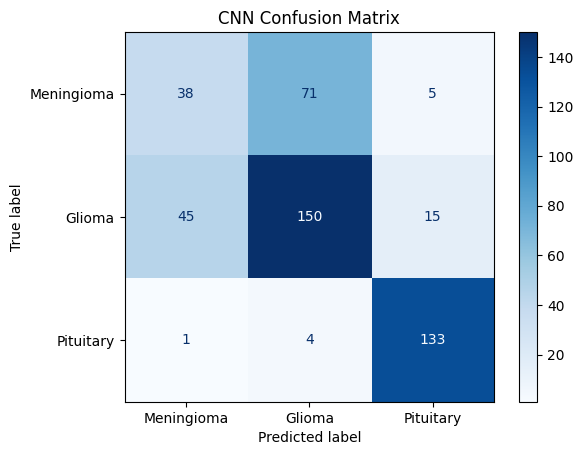

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, cnn_pred_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Meningioma", "Glioma", "Pituitary"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("CNN Confusion Matrix")
plt.show()

## **29. ResNet50 Transfer Learning**

I use ResNet50 with ImageNet pretrained weights and fine-tuning to classify brain tumors. I load my previously trained model to evaluate its performance and compare it with the baseline CNN.

In [ ]:
# Path to the previously trained ResNet50 model
resnet_path = os.path.join(
    project_path, "Models", "resnet50_finetuned_best.keras"
)

# Load the saved model
resnet_model = keras.models.load_model(resnet_path)

print("ResNet50 model loaded successfully!")

ResNet50 model loaded successfully!


## **30. Inspect the ResNet50 Model**

I inspect the saved ResNet50 model to confirm its architecture and the number of tumor classes it predicts.

In [ ]:
# Display the saved model architecture
resnet_model.summary()

# Check the input and output shapes
print("Input shape:", resnet_model.input_shape)
print("Output shape:", resnet_model.output_shape)

Model: "Brain_Tumor_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ data_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │    262,272 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 3)         │        387 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 53,233,035 (203.07 MB)

 Trainable params: 14,691,331 (56.04 MB)

 Non-trainable params: 9,159,040 (34.94 MB)

 Optimizer params: 29,382,664 (112.09 MB)

Input shape: (None, 224, 224, 3)
Output shape: (None, 3)


## 31. ResNet50 Test Evaluation

I evaluate the fine-tuned ResNet50 model on the same held-out test dataset used for the CNN. This allows me to compare their classification performance.

In [ ]:
# Evaluate the saved ResNet50 model
resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    X_test, y_test, verbose=1
)

print(f"ResNet50 Test Accuracy: {resnet_test_accuracy * 100:.2f}%")
print(f"ResNet50 Test Loss: {resnet_test_loss:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 82s 5s/step - accuracy: 0.8225 - loss: 0.4412
ResNet50 Test Accuracy: 82.25%
ResNet50 Test Loss: 0.4412


## 32. Verify ResNet50 Predictions

I check the model's predictions and compare them with the actual labels to investigate differences from my original evaluation.

In [ ]:
# Generate predictions
resnet_predictions = resnet_model.predict(X_test)

# Get predicted class labels
resnet_pred_labels = np.argmax(resnet_predictions, axis=1)

# Compare the number of actual and predicted labels
print("Actual labels:", np.bincount(y_test, minlength=3))
print("Predicted labels:", np.bincount(resnet_pred_labels, minlength=3))

# Check the number of correct predictions
correct = np.sum(resnet_pred_labels == y_test)

print("Correct predictions:", correct, "out of", len(y_test))

15/15 ━━━━━━━━━━━━━━━━━━━━ 84s 5s/step
Actual labels: [114 210 138]
Predicted labels: [ 70 244 148]
Correct predictions: 380 out of 462


## Step 33 — Check the Preprocessed Images
Let's verify that the images we're passing to ResNet50 have the expected pixel values and three identical grayscale channels.

In [ ]:
print("Image shape:", X_test.shape)
print("Minimum pixel value:", X_test.min())
print("Maximum pixel value:", X_test.max())

print("Channel 1 matches channel 2:",
      np.allclose(X_test[:, :, :, 0], X_test[:, :, :, 1]))

print("Channel 2 matches channel 3:",
      np.allclose(X_test[:, :, :, 1], X_test[:, :, :, 2]))

Image shape: (462, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Channel 1 matches channel 2: True
Channel 2 matches channel 3: True


## 34. ResNet50 Test Preprocessing

I prepare the test images using the same preprocessing method applied during ResNet50 training to ensure consistent evaluation.

In [ ]:
# Original preprocessing method
def preprocess_resnet_image(file_name):
    file_path = os.path.join(mri_path, file_name)

    with h5py.File(file_path, "r") as f:
        image = np.array(
            f["cjdata"]["image"],
            dtype=np.float32
        )

    image = cv2.resize(
        image, (224, 224),
        interpolation=cv2.INTER_AREA
    )

    min_val = image.min()
    max_val = image.max()

    if max_val > min_val:
        image = (image - min_val) / (max_val - min_val)
    else:
        image = np.zeros_like(image)

    image = np.stack([image] * 3, axis=-1)

    return image.astype(np.float32)


# Reload only the test images
test_rows = split_df[split_df["split"] == "test"]

X_test_resnet = np.array([
    preprocess_resnet_image(file_name)
    for file_name in test_rows["file_name"]
])

print("ResNet50 test images:", X_test_resnet.shape)

ResNet50 test images: (462, 224, 224, 3)


## 35. ResNet50 Test Evaluation

I evaluate the fine-tuned ResNet50 model on the held-out test images to measure its classification accuracy and loss.

In [ ]:
# Evaluate ResNet50 using the prepared test images
resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    X_test_resnet,
    y_test,
    verbose=1
)

print(f"ResNet50 Test Accuracy: {resnet_test_accuracy * 100:.2f}%")
print(f"ResNet50 Test Loss: {resnet_test_loss:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 76s 5s/step - accuracy: 0.9091 - loss: 0.2707
ResNet50 Test Accuracy: 90.91%
ResNet50 Test Loss: 0.2707


## 36. ResNet50 Classification Report

I calculate precision, recall, and F1-score for each tumor class to evaluate ResNet50's classification performance.

In [ ]:
# Predict tumor classes using ResNet50
resnet_predictions = resnet_model.predict(X_test_resnet)

# Convert probabilities into class labels
resnet_pred_labels = np.argmax(resnet_predictions, axis=1)

# Display classification report
print(classification_report(
    y_test,
    resnet_pred_labels,
    labels=[0, 1, 2],
    target_names=["Meningioma", "Glioma", "Pituitary"]
))

15/15 ━━━━━━━━━━━━━━━━━━━━ 77s 5s/step
              precision    recall  f1-score   support

  Meningioma       0.95      0.80      0.87       114
      Glioma       0.89      0.96      0.92       210
   Pituitary       0.91      0.92      0.92       138

    accuracy                           0.91       462
   macro avg       0.92      0.89      0.90       462
weighted avg       0.91      0.91      0.91       462



## 37. ResNet50 Confusion Matrix

I use a confusion matrix to examine correct and incorrect predictions for each tumor class and identify the most common classification errors.

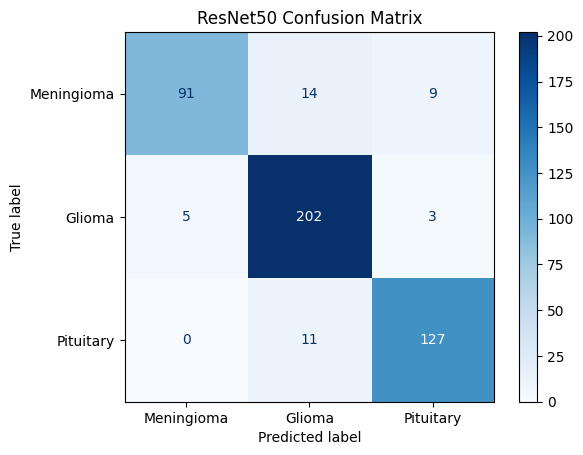

In [ ]:
# Create the ResNet50 confusion matrix
resnet_cm = confusion_matrix(y_test, resnet_pred_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=resnet_cm,
    display_labels=["Meningioma", "Glioma", "Pituitary"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet50 Confusion Matrix")
plt.show()

## 38. CNN and ResNet50 Comparison

I compare the classification performance of the baseline CNN and fine-tuned ResNet50 using test accuracy and macro F1-score.

This comparison helps me understand the benefit of transfer learning for brain tumor classification.

In [ ]:
comparison = pd.DataFrame({
    "Model": ["CNN", "ResNet50"],
    "Test Accuracy (%)": [
        cnn_test_accuracy * 100,
        resnet_test_accuracy * 100
    ],
    "Macro F1-Score": [
        0.66,
        0.90
    ]
})

print(comparison.round(2))

      Model  Test Accuracy (%)  Macro F1-Score
0       CNN              69.48            0.66
1  ResNet50              90.91            0.90


## 39. Grad-CAM Explainability

I use Grad-CAM to visualize which regions of the MRI images influence ResNet50's predictions.

Grad-CAM generates heatmaps that highlight areas contributing to a predicted tumor class. I also examine whether these highlighted regions overlap with the actual tumor locations.

In [ ]:
# Identify the ResNet50 backbone
resnet_backbone = resnet_model.get_layer("resnet50")

# Identify the final convolutional layer
last_conv_layer = resnet_backbone.get_layer("conv5_block3_out")

print("Backbone:", resnet_backbone.name)
print("Grad-CAM layer:", last_conv_layer.name)
print("Feature map shape:", last_conv_layer.output.shape)

Backbone: resnet50
Grad-CAM layer: conv5_block3_out
Feature map shape: (None, 7, 7, 2048)


## **40. Prepare the Grad-CAM Model**

I prepare Grad-CAM to extract the final convolutional features and classification predictions from ResNet50. These will be used to generate heatmaps showing which image regions influence the model's decisions.

In [ ]:
# Extract the final convolutional features
gradcam_backbone = keras.Model(
    inputs=resnet_backbone.input,
    outputs=[
        last_conv_layer.output,
        resnet_backbone.output
    ]
)

print("Grad-CAM feature extractor is ready!")
print("Feature map:", gradcam_backbone.output[0].shape)
print("Backbone output:", gradcam_backbone.output[1].shape)

Grad-CAM feature extractor is ready!
Feature map: (None, 7, 7, 2048)
Backbone output: (None, 7, 7, 2048)


## **41. Prepare the Classification Head**

I identify the classification layers after the ResNet50 backbone. These layers convert the extracted image features into predictions for the three tumor classes.

In [ ]:
# Classification layers after ResNet50
classification_layers = [
    "global_average_pooling2d_1",
    "dropout_1",
    "dense_2",
    "dropout_2",
    "dense_3"
]

# Display each layer
for layer_name in classification_layers:
    layer = resnet_model.get_layer(layer_name)
    print(layer.name, "-", layer.__class__.__name__)

global_average_pooling2d_1 - GlobalAveragePooling2D
dropout_1 - Dropout
dense_2 - Dense
dropout_2 - Dropout
dense_3 - Dense


## **42. Generate Grad-CAM Heatmaps**

I use Grad-CAM to identify which MRI regions contribute to ResNet50's predictions. The method calculates gradients from the predicted class and uses them to highlight important image regions.

In [ ]:
def make_gradcam_heatmap(image):
    # Convert one image into a batch
    image_batch = tf.convert_to_tensor(
        image[None, ...], dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        # Apply the model's input preprocessing
        x = image_batch

        for layer in resnet_model.layers[1:]:
            if layer.name == "resnet50":
                break
            x = layer(x, training=False)

        # Extract ResNet50 convolutional features
        conv_output, x = gradcam_backbone(x, training=False)
        tape.watch(conv_output)

        # Apply the classification layers
        for layer_name in classification_layers:
            layer = resnet_model.get_layer(layer_name)
            x = layer(x, training=False)

        # Select the predicted class
        predicted_class = tf.argmax(x[0])
        class_score = x[:, predicted_class]

    # Calculate gradients
    gradients = tape.gradient(class_score, conv_output)

    # Average gradients across spatial positions
    weights = tf.reduce_mean(gradients, axis=(1, 2))

    # Create the heatmap
    heatmap = tf.reduce_sum(
        conv_output * weights[:, None, None, :],
        axis=-1
    )

    heatmap = tf.maximum(heatmap[0], 0)

    # Normalize between 0 and 1
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()


print("Grad-CAM function is ready!")

Grad-CAM function is ready!


## **43. Grad-CAM Visualization**

I visualize the original MRI, the Grad-CAM heatmap, and the heatmap overlay to examine which regions influence ResNet50's prediction.

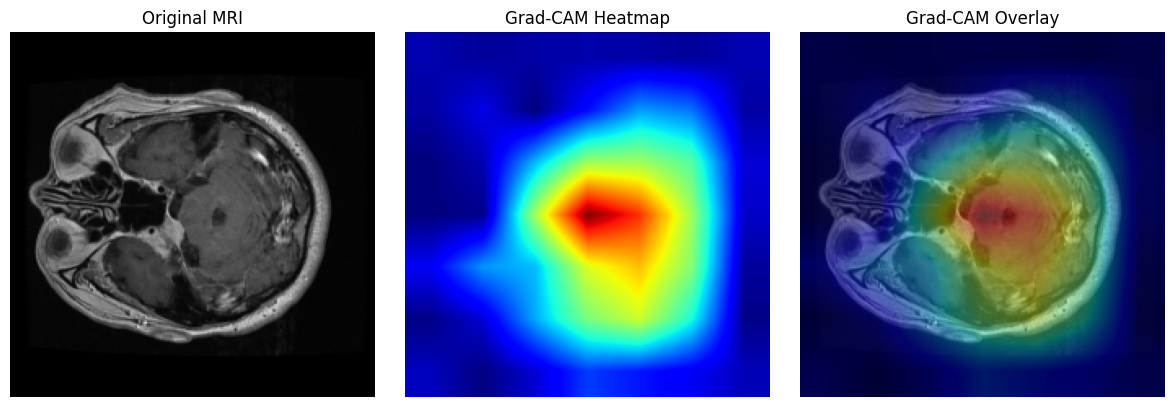

In [ ]:
# Select one test MRI image
image = X_test_resnet[0]

# Generate its Grad-CAM heatmap
heatmap = make_gradcam_heatmap(image)

# Resize heatmap to match the MRI
heatmap_resized = cv2.resize(heatmap, (224, 224))

# Create a colored heatmap
heatmap_color = plt.get_cmap("jet")(heatmap_resized)[:, :, :3]

# Overlay the heatmap on the MRI
overlay = 0.6 * image + 0.4 * heatmap_color
overlay = np.clip(overlay, 0, 1)

# Display the results
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image[:, :, 0], cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## **44. Grad-CAM Prediction Analysis**

I compare the actual tumor class with ResNet50's predicted class to understand the classification result alongside its Grad-CAM visualization.

In [ ]:
# Tumor class names
tumor_names = ["Meningioma", "Glioma", "Pituitary"]

# Use the same image as Step 43
image_index = 0

actual_label = y_test[image_index]
predicted_label = resnet_pred_labels[image_index]

confidence = resnet_predictions[image_index][predicted_label]

print("Actual tumor:", tumor_names[actual_label])
print("Predicted tumor:", tumor_names[predicted_label])
print(f"Confidence: {confidence * 100:.2f}%")

if actual_label == predicted_label:
    print("Classification: Correct")
else:
    print("Classification: Incorrect")

Actual tumor: Meningioma
Predicted tumor: Pituitary
Confidence: 94.38%
Classification: Incorrect


## **45. Grad-CAM for a Correct Prediction**

I examine a correctly classified MRI to compare its Grad-CAM visualization with the previous incorrect prediction.

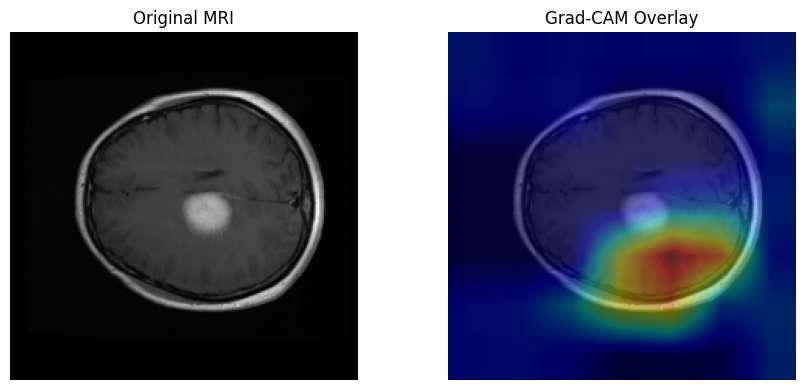

Actual: Meningioma
Predicted: Meningioma
Confidence: 78.88%


In [ ]:
# Find the first correctly classified test image
correct_indices = np.where(resnet_pred_labels == y_test)[0]
image_index = correct_indices[0]

# Select the image and generate Grad-CAM
image = X_test_resnet[image_index]
heatmap = make_gradcam_heatmap(image)

# Resize the heatmap
heatmap_resized = cv2.resize(heatmap, (224, 224))

# Create the overlay
heatmap_color = plt.get_cmap("jet")(heatmap_resized)[:, :, :3]
overlay = np.clip(0.6 * image + 0.4 * heatmap_color, 0, 1)

# Display MRI and Grad-CAM
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image[:, :, 0], cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(overlay)
axes[1].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Display prediction details
actual = y_test[image_index]
predicted = resnet_pred_labels[image_index]
confidence = resnet_predictions[image_index][predicted]

print("Actual:", tumor_names[actual])
print("Predicted:", tumor_names[predicted])
print(f"Confidence: {confidence * 100:.2f}%")

## **46. Grad-CAM Localization Analysis**

I evaluate whether Grad-CAM highlights the actual tumor regions using Intersection over Union (IoU).

IoU measures the overlap between the highlighted regions and the tumor masks. A higher IoU indicates better overlap.

In [ ]:
# Load the saved Grad-CAM evaluation results
gradcam_results_path = os.path.join(
    project_path, "gradcam_full_test_results.csv"
)

gradcam_results = pd.read_csv(gradcam_results_path)

print("Total evaluated images:", len(gradcam_results))
print("Available columns:")
print(gradcam_results.columns.tolist())

display(gradcam_results.head())

Total evaluated images: 462
Available columns:
['file_name', 'true_class', 'predicted_class', 'correct', 'confidence', 'tumor_attention_percent', 'gradcam_mask_iou']


,file_name,true_class,predicted_class,correct,confidence,tumor_attention_percent,gradcam_mask_iou
0,6.mat,Meningioma,Pituitary,False,94.376570,2.027856,0.034788
1,7.mat,Meningioma,Pituitary,False,99.743286,1.287636,0.002867
2,8.mat,Meningioma,Pituitary,False,98.824196,0.105803,0.000000
3,9.mat,Meningioma,Glioma,False,62.347370,0.078509,0.000000
4,10.mat,Meningioma,Meningioma,True,78.879090,8.778816,0.128702


## Image to see

In [ ]:
# Inspect the tumor mask stored in an MRI file

sample_file = gradcam_results.iloc[0]["file_name"]
sample_path = os.path.join(mri_path, sample_file)

with h5py.File(sample_path, "r") as f:
    print("Available fields:", list(f["cjdata"].keys()))

    if "tumorMask" in f["cjdata"]:
        mask = np.array(f["cjdata"]["tumorMask"])
        print("Tumor mask shape:", mask.shape)
        print("Unique mask values:", np.unique(mask))

Available fields: ['PID', 'image', 'label', 'tumorBorder', 'tumorMask']
Tumor mask shape: (512, 512)
Unique mask values: [0 1]


### **46A. Visual Comparison of Tumor Annotation and Grad-CAM**

I compare the annotated tumor region with the Grad-CAM explanation for a test MRI image.

This visualization helps determine whether the regions influencing ResNet50's prediction overlap with the actual tumor location.

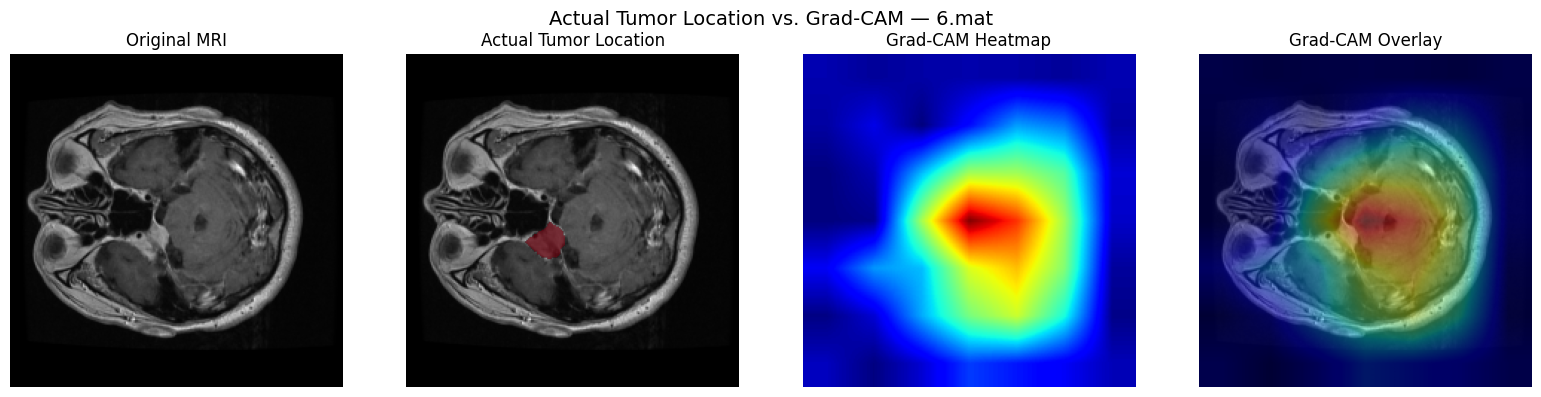

In [ ]:
# Step 46A: Visual Comparison of Tumor Annotation and Grad-CAM

import numpy as np
import matplotlib.pyplot as plt
import cv2
import h5py
import os

# Select a test MRI image
idx = 0

file_name = test_rows.iloc[idx]["file_name"]
file_path = os.path.join(mri_path, file_name)

# Load the annotated tumor mask
with h5py.File(file_path, "r") as f:
    tumor_mask = np.array(f["cjdata"]["tumorMask"])

# Resize mask to match the model input
tumor_mask = cv2.resize(
    tumor_mask.astype(np.uint8),
    (224, 224),
    interpolation=cv2.INTER_NEAREST
)

# Load the corresponding preprocessed MRI
image = X_test_resnet[idx]

# Generate Grad-CAM heatmap
heatmap = make_gradcam_heatmap(image)

# Resize heatmap to match MRI dimensions
heatmap = cv2.resize(
    heatmap,
    (224, 224)
)

# Convert Grad-CAM heatmap to color
heatmap_color = plt.cm.jet(heatmap)[..., :3]

# Create Grad-CAM overlay
overlay = np.clip(
    0.6 * image + 0.4 * heatmap_color,
    0,
    1
)

# Mask the background so only the tumor is highlighted
masked_tumor = np.ma.masked_where(
    tumor_mask == 0,
    tumor_mask
)

# Create four-panel visualization
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Panel 1: Original MRI
axes[0].imshow(image)
axes[0].set_title("Original MRI")

# Panel 2: Actual tumor highlighted on MRI
axes[1].imshow(image)
axes[1].imshow(
    masked_tumor,
    cmap="Reds",
    alpha=0.7,
    vmin=0,
    vmax=1
)
axes[1].set_title("Actual Tumor Location")

# Panel 3: Grad-CAM heatmap
axes[2].imshow(
    heatmap,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[2].set_title("Grad-CAM Heatmap")

# Panel 4: Grad-CAM overlay
axes[3].imshow(overlay)
axes[3].set_title("Grad-CAM Overlay")

# Remove axes
for ax in axes:
    ax.axis("off")

# Overall title
plt.suptitle(
    f"Actual Tumor Location vs. Grad-CAM — {file_name}",
    fontsize=14
)

plt.tight_layout()
plt.show()

### **46B. Calculating Tumor Attention and Grad-CAM IoU**

I calculate two quantitative measures to evaluate Grad-CAM localization.

Tumor attention percentage measures the proportion of total Grad-CAM activation that falls within the annotated tumor region.

Intersection over Union (IoU) measures the overlap between a thresholded Grad-CAM region and the annotated tumor mask.

Higher values indicate greater localization agreement under the selected evaluation method.


In [ ]:
# Step 46B: Calculate Tumor Attention and Grad-CAM IoU

# Convert the annotated tumor mask to binary
mask_binary = tumor_mask > 0

# Tumor attention: percentage of total heatmap activation inside tumor
total_attention = np.sum(heatmap)
tumor_attention = np.sum(heatmap[mask_binary])

tumor_attention_percent = (
    tumor_attention / (total_attention + 1e-8)
) * 100

# Threshold the Grad-CAM heatmap at 50% of its maximum
threshold = 0.5
gradcam_binary = heatmap >= threshold

# Calculate Intersection over Union (IoU)
intersection = np.logical_and(
    gradcam_binary, mask_binary
).sum()

union = np.logical_or(
    gradcam_binary, mask_binary
).sum()

gradcam_iou = intersection / (union + 1e-8)

# Display results
print("MRI File:", file_name)
print(f"Tumor Attention: {tumor_attention_percent:.2f}%")
print(f"Grad-CAM IoU: {gradcam_iou:.4f}")

# Compare with previously saved evaluation results
saved_result = gradcam_results[
    gradcam_results["file_name"] == file_name
]

if not saved_result.empty:
    print("\nPreviously saved results:")
    print(
        "Tumor Attention:",
        f"{saved_result.iloc[0]['tumor_attention_percent']:.2f}%"
    )
    print(
        "Grad-CAM IoU:",
        f"{saved_result.iloc[0]['gradcam_mask_iou']:.4f}"
    )

MRI File: 6.mat
Tumor Attention: 2.31%
Grad-CAM IoU: 0.0468

Previously saved results:
Tumor Attention: 2.03%
Grad-CAM IoU: 0.0348


## **47. Grad-CAM Localization Results**

I calculate the average tumor attention and IoU across the test dataset to evaluate how well Grad-CAM highlights actual tumor regions.

I also compare localization performance between correct and incorrect classifications.

In [ ]:
# Overall localization results
mean_attention = gradcam_results["tumor_attention_percent"].mean()
mean_iou = gradcam_results["gradcam_mask_iou"].mean()
median_iou = gradcam_results["gradcam_mask_iou"].median()

print(f"Mean tumor attention: {mean_attention:.2f}%")
print(f"Mean IoU: {mean_iou:.4f}")
print(f"Median IoU: {median_iou:.4f}")

# Compare correct and incorrect predictions
iou_comparison = gradcam_results.groupby("correct")[
    "gradcam_mask_iou"
].mean()

print("\nMean IoU by classification result:")
print(iou_comparison)

Mean tumor attention: 5.93%
Mean IoU: 0.0928
Median IoU: 0.0424

Mean IoU by classification result:
correct
False    0.046171
True     0.097483
Name: gradcam_mask_iou, dtype: float64


## **48. Grad-CAM Localization Comparison**

I compare the average Grad-CAM IoU for correctly and incorrectly classified MRI images to examine the relationship between classification and localization performance.

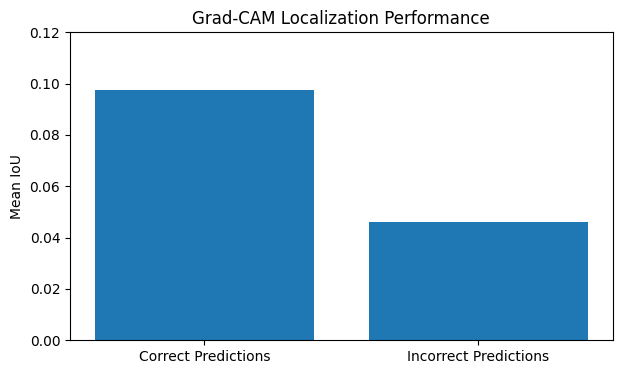

In [ ]:
# Calculate average IoU for both groups
correct_iou = gradcam_results[
    gradcam_results["correct"] == True
]["gradcam_mask_iou"].mean()

incorrect_iou = gradcam_results[
    gradcam_results["correct"] == False
]["gradcam_mask_iou"].mean()

# Create a comparison chart
plt.figure(figsize=(7, 4))

plt.bar(
    ["Correct Predictions", "Incorrect Predictions"],
    [correct_iou, incorrect_iou]
)

plt.ylabel("Mean IoU")
plt.title("Grad-CAM Localization Performance")
plt.ylim(0, 0.12)

plt.show()

## **49. Reliability Analysis**

I evaluate ResNet50's prediction stability under small brightness and contrast changes.

I increase brightness by 5% and contrast by 5%, then compare the predictions with the original MRI images.

In [ ]:
# Original test predictions
original_predictions = resnet_pred_labels
original_accuracy = np.mean(original_predictions == y_test)

# Apply small brightness and contrast changes
brightness_images = np.clip(X_test_resnet + 0.05, 0, 1)

contrast_images = np.clip(
    (X_test_resnet - 0.5) * 1.05 + 0.5,
    0, 1
)

print("Original test images:", X_test_resnet.shape)
print("Brightness images:", brightness_images.shape)
print("Contrast images:", contrast_images.shape)
print(f"Original accuracy: {original_accuracy * 100:.2f}%")

Original test images: (462, 224, 224, 3)
Brightness images: (462, 224, 224, 3)
Contrast images: (462, 224, 224, 3)
Original accuracy: 90.91%


## **50. Evaluate Prediction Stability**

I evaluate ResNet50 on MRI images with small brightness and contrast changes.

I compare the accuracy and prediction stability under each condition to understand how sensitive the model is to these image variations.

In [ ]:
# Predict using modified MRI images
brightness_probs = resnet_model.predict(
    brightness_images, batch_size=32
)

contrast_probs = resnet_model.predict(
    contrast_images, batch_size=32
)

# Get predicted classes
brightness_predictions = np.argmax(brightness_probs, axis=1)
contrast_predictions = np.argmax(contrast_probs, axis=1)

# Calculate accuracy
brightness_accuracy = np.mean(brightness_predictions == y_test)
contrast_accuracy = np.mean(contrast_predictions == y_test)

# Calculate prediction stability
brightness_stability = np.mean(
    brightness_predictions == original_predictions
)

contrast_stability = np.mean(
    contrast_predictions == original_predictions
)

print(f"Original Accuracy: {original_accuracy * 100:.2f}%")

print("\nBrightness +5%")
print(f"Accuracy: {brightness_accuracy * 100:.2f}%")
print(f"Prediction Stability: {brightness_stability * 100:.2f}%")

print("\nContrast +5%")
print(f"Accuracy: {contrast_accuracy * 100:.2f}%")
print(f"Prediction Stability: {contrast_stability * 100:.2f}%")

15/15 ━━━━━━━━━━━━━━━━━━━━ 79s 5s/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 81s 5s/step
Original Accuracy: 90.91%

Brightness +5%
Accuracy: 90.04%
Prediction Stability: 98.48%

Contrast +5%
Accuracy: 91.34%
Prediction Stability: 98.92%


## **51. Reliability Results Visualization**

I compare ResNet50's classification accuracy on original MRI images and images with small brightness and contrast changes.

This helps me visualize how the changes affect classification performance.

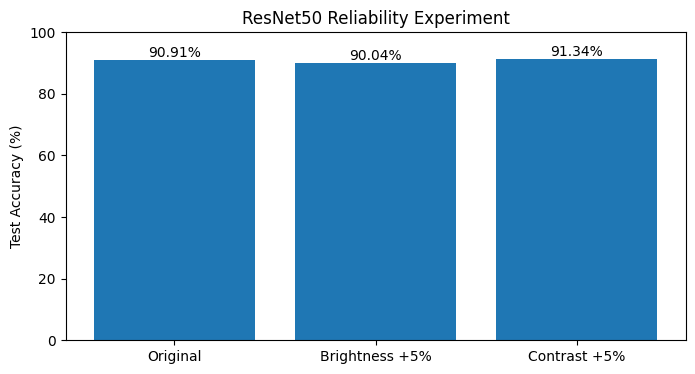

In [ ]:
conditions = ["Original", "Brightness +5%", "Contrast +5%"]

accuracies = [
    original_accuracy * 100,
    brightness_accuracy * 100,
    contrast_accuracy * 100
]

plt.figure(figsize=(8, 4))

bars = plt.bar(conditions, accuracies)

plt.ylabel("Test Accuracy (%)")
plt.title("ResNet50 Reliability Experiment")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.show()

## 52. Test MRI Predictions

I display sample MRI images from the held-out test dataset, showing their actual tumor classes, predicted classes, and prediction confidence.

This helps me examine individual correct and incorrect predictions.

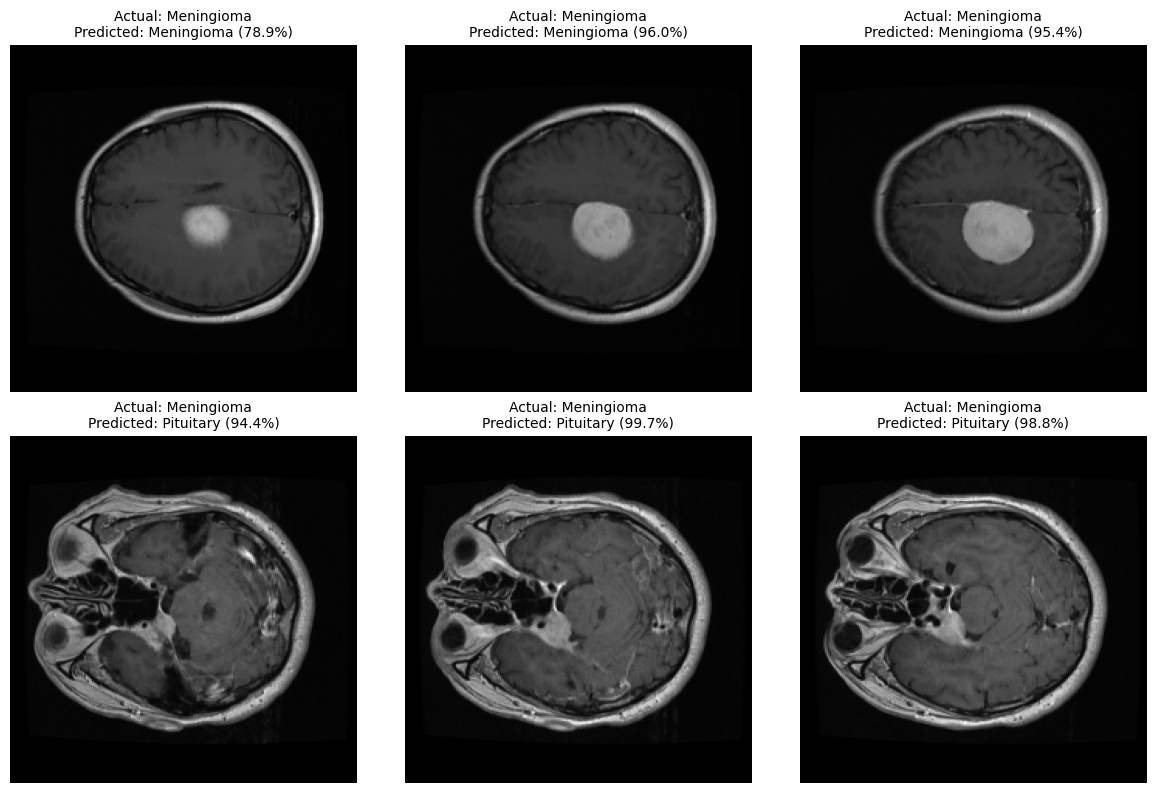

In [ ]:
# Select three correct and three incorrect predictions
correct_indices = np.where(resnet_pred_labels == y_test)[0][:3]
incorrect_indices = np.where(resnet_pred_labels != y_test)[0][:3]

sample_indices = np.concatenate([
    correct_indices,
    incorrect_indices
])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, idx in zip(axes.flat, sample_indices):
    image = X_test_resnet[idx]

    actual = tumor_names[y_test[idx]]
    predicted = tumor_names[resnet_pred_labels[idx]]
    confidence = resnet_predictions[idx][resnet_pred_labels[idx]] * 100

    ax.imshow(image[:, :, 0], cmap="gray")
    ax.set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted} ({confidence:.1f}%)",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## 53. Consistent Image Preprocessing

I use the same image orientation, resizing, and normalization method for both models to ensure a fair comparison.

In [ ]:
# Prepare CNN training images using the same preprocessing
train_rows = split_df[split_df["split"] == "train"]
val_rows = split_df[split_df["split"] == "validation"]

X_train_aligned = np.array([
    preprocess_resnet_image(file_name)
    for file_name in train_rows["file_name"]
], dtype=np.float32)

X_val_aligned = np.array([
    preprocess_resnet_image(file_name)
    for file_name in val_rows["file_name"]
], dtype=np.float32)

print("Training images:", X_train_aligned.shape)
print("Validation images:", X_val_aligned.shape)
print("Test images:", X_test_resnet.shape)

Training images: (2177, 224, 224, 3)
Validation images: (425, 224, 224, 3)
Test images: (462, 224, 224, 3)


## **54. Train CNN with Consistent Preprocessing**

I train the baseline CNN using the same image preprocessing applied to ResNet50. This ensures that both models are evaluated under comparable conditions.

In [ ]:
# Create a fresh CNN with the same architecture
cnn_aligned = keras.models.clone_model(cnn_model)

# Compile the model
cnn_aligned.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Check the model
cnn_aligned.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

## **55. CNN Training with Consistent Preprocessing**

I train the baseline CNN using the same image preprocessing as ResNet50. I use data augmentation, class weights, and early stopping to support training and reduce overfitting.

In [ ]:
# Prepare training dataset
aligned_train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train_aligned, y_train)
)

aligned_train_ds = aligned_train_ds.shuffle(
    2177, seed=42
).batch(32)

# Apply augmentation to training images only
aligned_train_ds = aligned_train_ds.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    )
)

# Save the best aligned CNN separately
aligned_save_path = os.path.join(
    project_path, "Models", "cnn_aligned_best.keras"
)

aligned_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        aligned_save_path,
        monitor="val_loss",
        save_best_only=True
    )
]

# Train the CNN
aligned_history = cnn_aligned.fit(
    aligned_train_ds,
    validation_data=(X_val_aligned, y_val),
    epochs=30,
    callbacks=aligned_callbacks,
    class_weight=class_weights
)

Epoch 1/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 260s 4s/step - accuracy: 0.4773 - loss: 0.9785 - val_accuracy: 0.7082 - val_loss: 0.8018
Epoch 2/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 261s 4s/step - accuracy: 0.5825 - loss: 0.8591 - val_accuracy: 0.5694 - val_loss: 0.8361
Epoch 3/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 252s 4s/step - accuracy: 0.5999 - loss: 0.8333 - val_accuracy: 0.5788 - val_loss: 0.8149
Epoch 4/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 252s 4s/step - accuracy: 0.6086 - loss: 0.8140 - val_accuracy: 0.5765 - val_loss: 0.8175
Epoch 5/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 266s 4s/step - accuracy: 0.6008 - loss: 0.8112 - val_accuracy: 0.5624 - val_loss: 0.8391
Epoch 6/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 243s 3s/step - accuracy: 0.6059 - loss: 0.8114 - val_accuracy: 0.5012 - val_loss: 1.0738


## **56. CNN Test Evaluation**

I evaluate the retrained CNN on the held-out test dataset using the same preprocessing applied to ResNet50.

This allows a more consistent comparison between the two models.

In [ ]:
# Evaluate the retrained CNN
aligned_test_loss, aligned_test_accuracy = cnn_aligned.evaluate(
    X_test_resnet,
    y_test,
    verbose=1
)

print(f"CNN Test Accuracy: {aligned_test_accuracy * 100:.2f}%")
print(f"CNN Test Loss: {aligned_test_loss:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 891ms/step - accuracy: 0.6580 - loss: 0.7937
CNN Test Accuracy: 65.80%
CNN Test Loss: 0.7937


## **57. CNN Classification Performance by Tumor Type**

I examine precision, recall, and F1-score for each tumor class to identify where the retrained CNN performs well and where classification errors occur.

In [ ]:
# Generate predictions from the retrained CNN
aligned_predictions = cnn_aligned.predict(
    X_test_resnet,
    verbose=1
)

aligned_pred_labels = np.argmax(
    aligned_predictions,
    axis=1
)

# Classification report
from sklearn.metrics import classification_report

print("CNN Classification Report\n")

print(classification_report(
    y_test,
    aligned_pred_labels,
    target_names=["Meningioma", "Glioma", "Pituitary"],
    digits=4
))

15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 887ms/step
CNN Classification Report

              precision    recall  f1-score   support

  Meningioma     0.4211    0.2105    0.2807       114
      Glioma     0.6183    0.7714    0.6864       210
   Pituitary     0.8252    0.8551    0.8399       138

    accuracy                         0.6580       462
   macro avg     0.6215    0.6123    0.6023       462
weighted avg     0.6314    0.6580    0.6321       462



## **58. CNN Confusion Matrix**

I use a confusion matrix to examine the classification errors made by the retrained CNN across the three tumor categories.

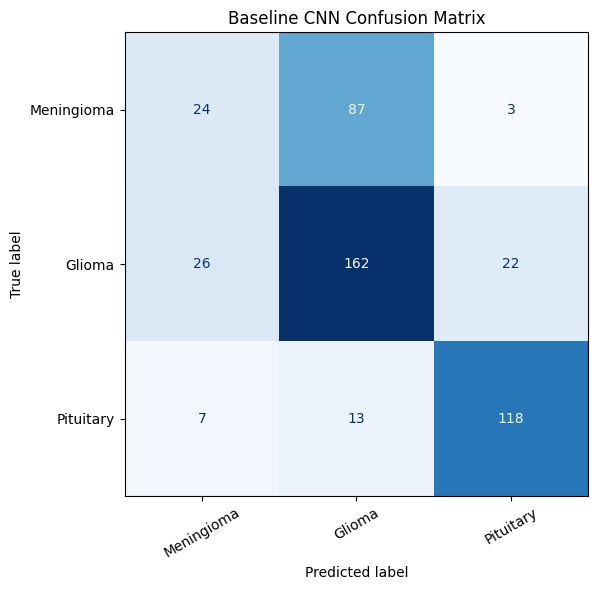

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = ["Meningioma", "Glioma", "Pituitary"]

# Calculate confusion matrix
aligned_cm = confusion_matrix(
    y_test,
    aligned_pred_labels
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=aligned_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Baseline CNN Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## **59. Final Model Performance Comparison**

I compare the baseline CNN and fine-tuned ResNet50 using the same held-out test images and consistent preprocessing. I report accuracy, precision, recall, and F1-score to assess overall performance and class-level balance.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

# Calculate macro-averaged metrics
cnn_precision, cnn_recall, cnn_f1, _ = precision_recall_fscore_support(
    y_test, aligned_pred_labels, average="macro", zero_division=0
)

resnet_precision, resnet_recall, resnet_f1, _ = precision_recall_fscore_support(
    y_test, resnet_pred_labels, average="macro", zero_division=0
)

# Create comparison table
final_comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "Fine-tuned ResNet50"],
    "Test Accuracy (%)": [
        aligned_test_accuracy * 100,
        resnet_test_accuracy * 100
    ],
    "Macro Precision": [cnn_precision, resnet_precision],
    "Macro Recall": [cnn_recall, resnet_recall],
    "Macro F1-score": [cnn_f1, resnet_f1]
})

display(final_comparison.round(4))

,Model,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1-score
0,Baseline CNN,65.8009,0.6215,0.6123,0.6023
1,Fine-tuned ResNet50,90.9091,0.9172,0.8935,0.9027


## **60. Visualization of Model Performance**

I visualize the classification accuracy and macro F1-score of both models to compare their predictive performance.

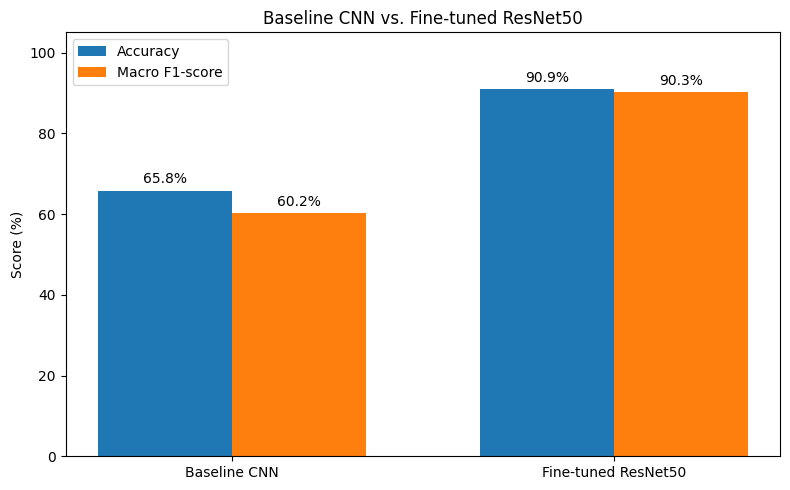

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

models = ["Baseline CNN", "Fine-tuned ResNet50"]

accuracy = [
    aligned_test_accuracy * 100,
    resnet_test_accuracy * 100
]

macro_f1 = [
    cnn_f1 * 100,
    resnet_f1 * 100
]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width / 2,
    accuracy,
    width,
    label="Accuracy"
)

bars2 = ax.bar(
    x + width / 2,
    macro_f1,
    width,
    label="Macro F1-score"
)

ax.set_ylabel("Score (%)")
ax.set_title("Baseline CNN vs. Fine-tuned ResNet50")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 105)
ax.legend()

ax.bar_label(bars1, fmt="%.1f%%", padding=3)
ax.bar_label(bars2, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

## **61. Grad-CAM Visualization Across Correct and Incorrect Predictions**

I visualize Grad-CAM explanations for correctly and incorrectly classified MRI images.

Each example includes the original MRI image, Grad-CAM heatmap, and an overlay showing the regions that contributed to the model's prediction.

This qualitative analysis helps assess whether the model's attention aligns with visible tumor regions.

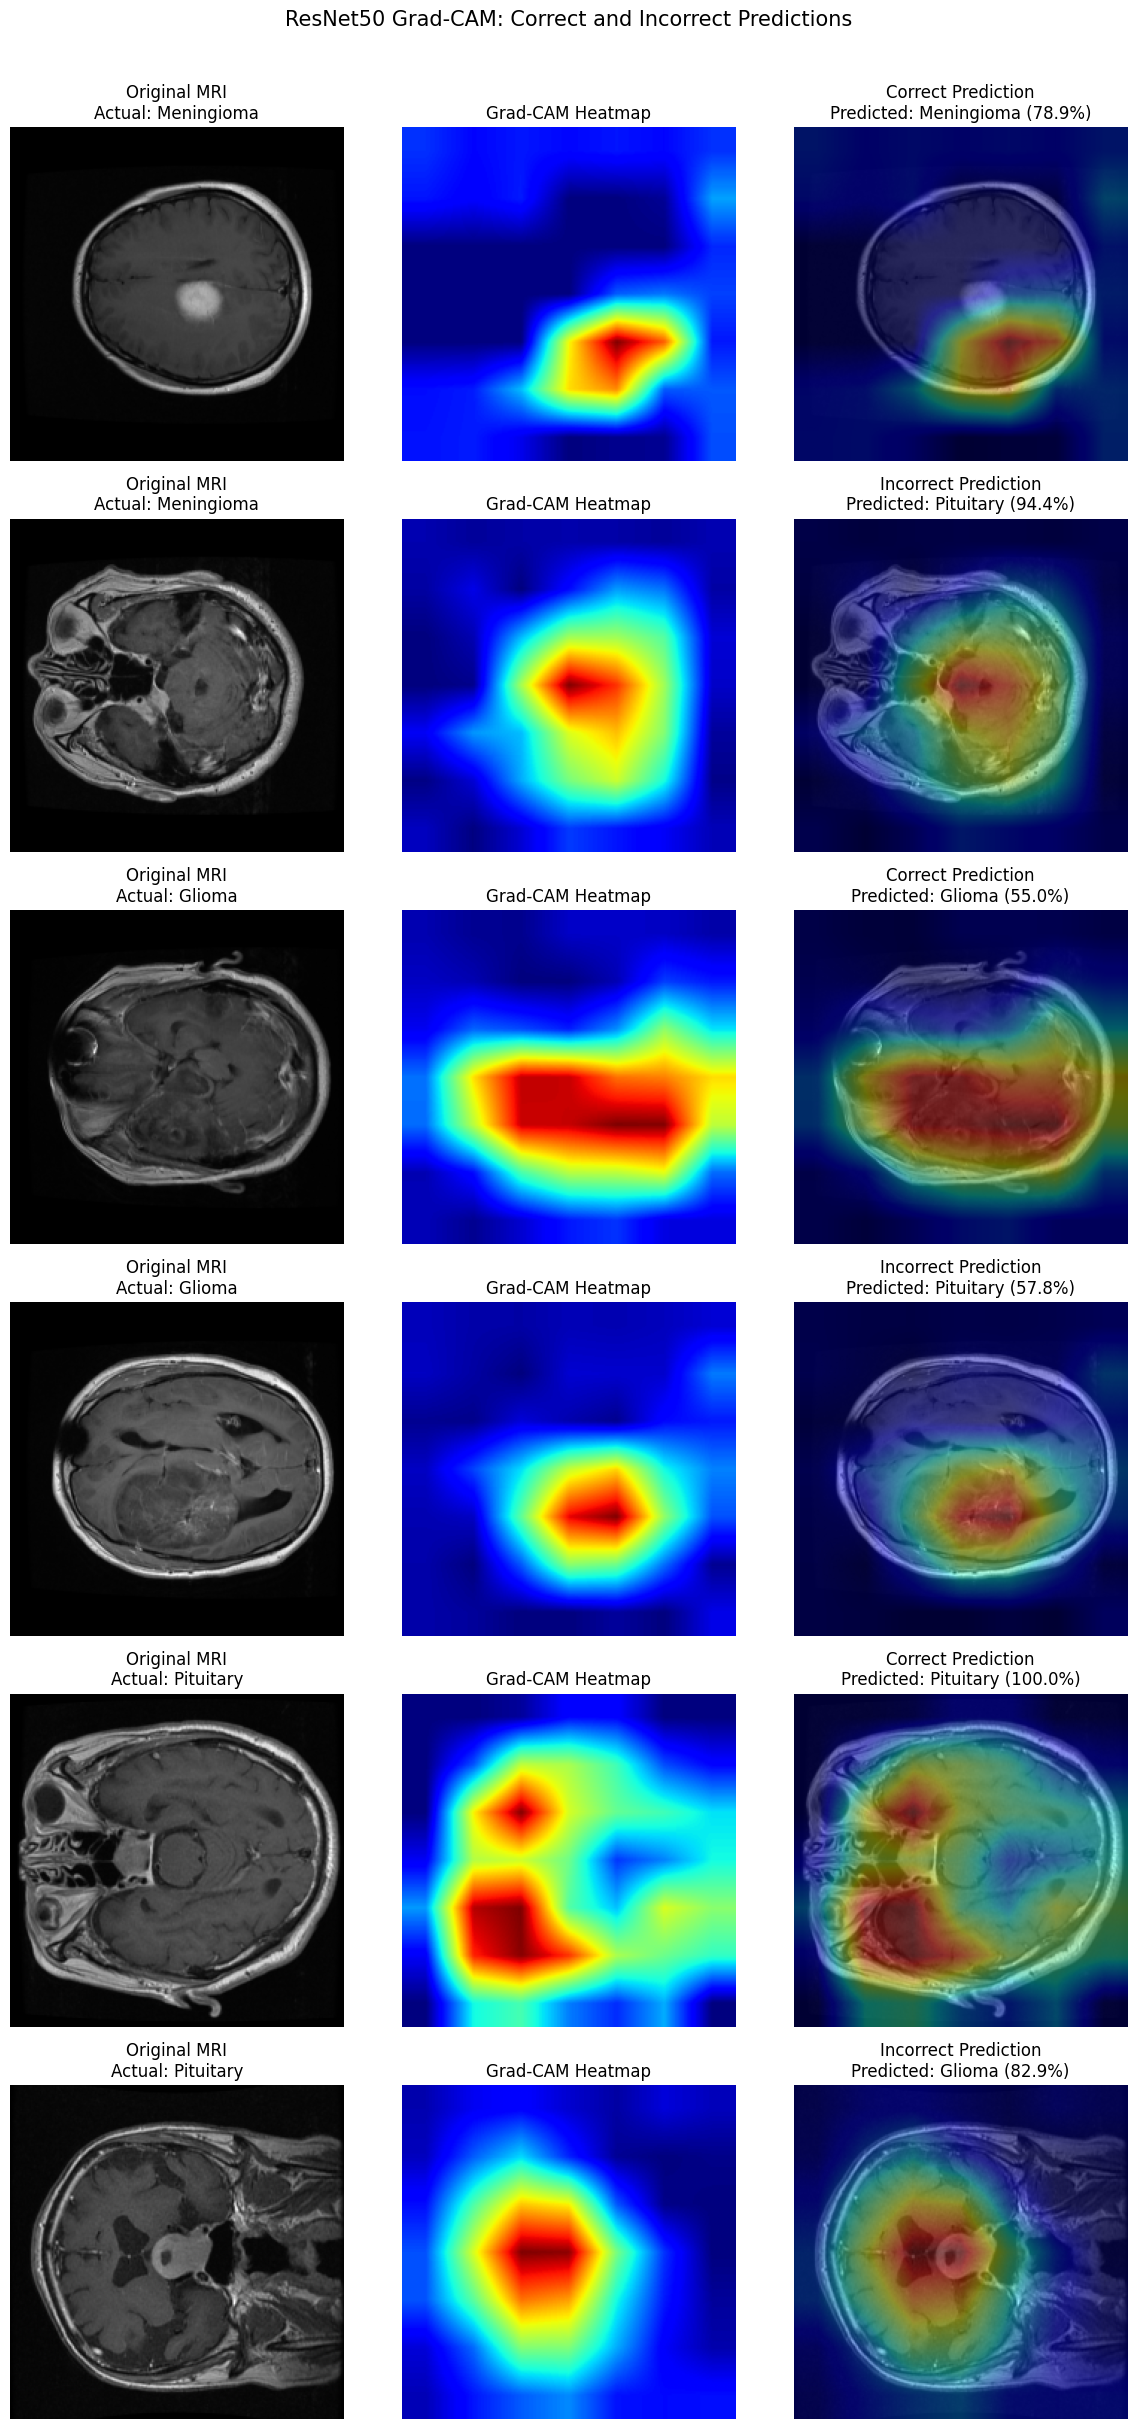

In [ ]:
# Step 61: Grad-CAM Visualization Across Tumor Classes

import numpy as np
import matplotlib.pyplot as plt
import cv2

class_names = ["Meningioma", "Glioma", "Pituitary"]

# Select one correct and one incorrect prediction per tumor class
selected_indices = []

for class_id in range(3):

    correct = np.where(
        (y_test == class_id) &
        (resnet_pred_labels == y_test)
    )[0]

    incorrect = np.where(
        (y_test == class_id) &
        (resnet_pred_labels != y_test)
    )[0]

    if len(correct) > 0:
        selected_indices.append(correct[0])

    if len(incorrect) > 0:
        selected_indices.append(incorrect[0])

# Create visualization
fig, axes = plt.subplots(
    len(selected_indices),
    3,
    figsize=(12, 4 * len(selected_indices)),
    squeeze=False
)

for row, idx in enumerate(selected_indices):

    image = X_test_resnet[idx]

    # Generate Grad-CAM heatmap
    heatmap = make_gradcam_heatmap(image)

    # Resize heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224)
    )

    # Convert heatmap to color
    heatmap_color = plt.cm.jet(
        heatmap_resized
    )[..., :3]

    # Overlay heatmap on MRI
    overlay = np.clip(
        0.6 * image + 0.4 * heatmap_color,
        0,
        1
    )

    # Actual and predicted tumor types
    actual = class_names[int(y_test[idx])]
    predicted = class_names[int(resnet_pred_labels[idx])]

    confidence = resnet_predictions[idx].max() * 100

    status = (
        "Correct"
        if y_test[idx] == resnet_pred_labels[idx]
        else "Incorrect"
    )

    # Original MRI
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(
        f"Original MRI\nActual: {actual}"
    )

    # Grad-CAM heatmap
    axes[row, 1].imshow(
        heatmap_resized,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title("Grad-CAM Heatmap")

    # Grad-CAM overlay
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(
        f"{status} Prediction\n"
        f"Predicted: {predicted} ({confidence:.1f}%)"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "ResNet50 Grad-CAM: Correct and Incorrect Predictions",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

In [ ]:
import os

for name in ["cnn_aligned_best.keras", "resnet50_finetuned_best.keras"]:
    path = os.path.join(project_path, "Models", name)
    print(name, "SAVED" if os.path.exists(path) else "NOT FOUND")

cnn_aligned_best.keras SAVED
resnet50_finetuned_best.keras SAVED


## Verify Grad-CAM calculations
Run this cell to confirm the differences between the newly calculated values and the saved results:

In [ ]:
print("GRAD-CAM VERIFICATION")
print(f"New tumor attention: {tumor_attention_percent:.4f}%")
print(f"Saved tumor attention: {saved_result.iloc[0]['tumor_attention_percent']:.4f}%")

print(f"New IoU: {gradcam_iou:.4f}")
print(f"Saved IoU: {saved_result.iloc[0]['gradcam_mask_iou']:.4f}")

print("\nStatus: Calculation methods require reconciliation.")

GRAD-CAM VERIFICATION
New tumor attention: 2.3087%
Saved tumor attention: 2.0279%
New IoU: 0.0468
Saved IoU: 0.0348

Status: Calculation methods require reconciliation.


In [ ]:
print("FINAL PROJECT CHECK")

required_files = [
    "Models/cnn_aligned_best.keras",
    "Models/resnet50_finetuned_best.keras",
    "gradcam_full_test_results.csv"
]

for name in required_files:
    path = os.path.join(project_path, name)
    print(f"{name}: {'SAVED' if os.path.isfile(path) else 'MISSING'}")

print("\nDataset split:", len(split_df), "images")
print("Test images:", len(test_rows))
print("Grad-CAM records:", len(gradcam_results))

FINAL PROJECT CHECK
Models/cnn_aligned_best.keras: SAVED
Models/resnet50_finetuned_best.keras: SAVED
gradcam_full_test_results.csv: SAVED

Dataset split: 3064 images
Test images: 462
Grad-CAM records: 462


## # Step 64 — Verify Required Variables for Grad-CAM Stability Experiment

In [ ]:
# Step 64 — Verify Required Variables for Grad-CAM Stability Experiment

required = [
    "resnet_model",
    "X_test_resnet",
    "y_test",
    "make_gradcam_heatmap"
]

for name in required:
    print(f"{name}: {'READY' if name in globals() else 'MISSING'}")

if "X_test_resnet" in globals():
    print("Test images:", X_test_resnet.shape)

resnet_model: READY
X_test_resnet: READY
y_test: READY
make_gradcam_heatmap: READY
Test images: (462, 224, 224, 3)


### **65. Grad-CAM Explanation Stability Under Image Perturbations**

This experiment evaluates whether Grad-CAM explanations remain stable when small brightness and contrast changes are applied to MRI images.

For each selected MRI image, Grad-CAM heatmaps are generated for the original image, a 5% brightness increase, and a 5% contrast increase.

The experiment compares the highlighted regions to determine whether small image changes affect the model's visual explanations.

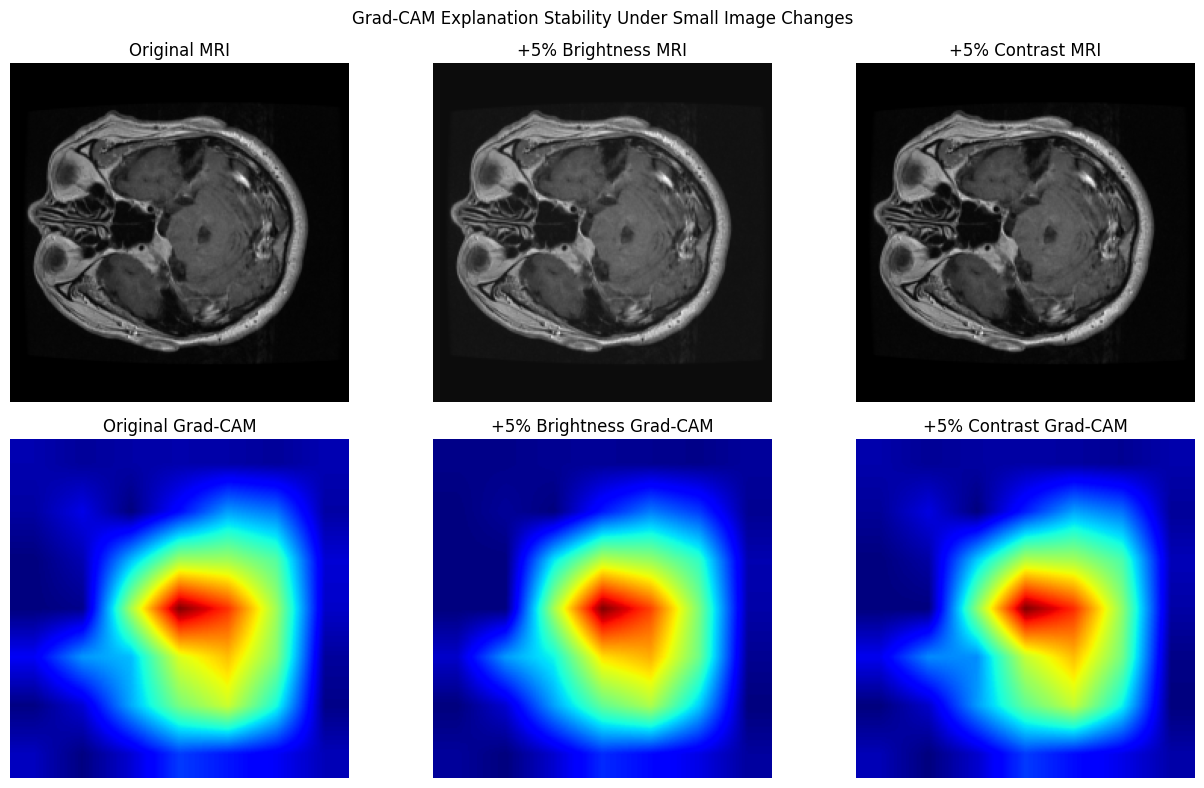

In [ ]:
# Step 65 — Grad-CAM Explanation Stability

import numpy as np
import matplotlib.pyplot as plt
import cv2

# Select one MRI image
idx = 0
original = X_test_resnet[idx].copy()

# Apply small perturbations
brightness = np.clip(original + 0.05, 0, 1)

contrast = np.clip(original * 1.05, 0, 1)

# Generate Grad-CAM heatmaps
heatmap_original = make_gradcam_heatmap(original)
heatmap_brightness = make_gradcam_heatmap(brightness)
heatmap_contrast = make_gradcam_heatmap(contrast)

# Resize heatmaps for consistent comparison
target_size = (224, 224)

heatmap_original = cv2.resize(heatmap_original, target_size)
heatmap_brightness = cv2.resize(heatmap_brightness, target_size)
heatmap_contrast = cv2.resize(heatmap_contrast, target_size)

# Display images and corresponding explanations
images = [original, brightness, contrast]
heatmaps = [
    heatmap_original,
    heatmap_brightness,
    heatmap_contrast
]

titles = ["Original", "+5% Brightness", "+5% Contrast"]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for i in range(3):
    axes[0, i].imshow(images[i])
    axes[0, i].set_title(titles[i] + " MRI")
    axes[0, i].axis("off")

    axes[1, i].imshow(heatmaps[i], cmap="jet", vmin=0, vmax=1)
    axes[1, i].set_title(titles[i] + " Grad-CAM")
    axes[1, i].axis("off")

plt.suptitle("Grad-CAM Explanation Stability Under Small Image Changes")
plt.tight_layout()
plt.show()

### **66. Quantitative Grad-CAM Explanation Stability**

Pearson correlation and Mean Absolute Error (MAE) are used to compare the original Grad-CAM heatmap with the heatmaps generated after 5% brightness and contrast changes.

A correlation close to 1 indicates that the heatmaps have similar spatial activation patterns. A lower MAE indicates smaller differences in activation intensity.

These metrics measure explanation consistency, not tumor localization accuracy.

In [ ]:
# Step 66 — Quantitative Grad-CAM Stability

import numpy as np

def compare_gradcam(original_heatmap, modified_heatmap):
    original_flat = original_heatmap.flatten()
    modified_flat = modified_heatmap.flatten()

    correlation = np.corrcoef(
        original_flat, modified_flat
    )[0, 1]

    mae = np.mean(
        np.abs(original_heatmap - modified_heatmap)
    )

    return correlation, mae


brightness_corr, brightness_mae = compare_gradcam(
    heatmap_original,
    heatmap_brightness
)

contrast_corr, contrast_mae = compare_gradcam(
    heatmap_original,
    heatmap_contrast
)

print("GRAD-CAM EXPLANATION STABILITY")
print("-" * 40)

print("\n5% Brightness Increase")
print(f"Pearson Correlation: {brightness_corr:.4f}")
print(f"Mean Absolute Error: {brightness_mae:.4f}")

print("\n5% Contrast Increase")
print(f"Pearson Correlation: {contrast_corr:.4f}")
print(f"Mean Absolute Error: {contrast_mae:.4f}")

GRAD-CAM EXPLANATION STABILITY
----------------------------------------

5% Brightness Increase
Pearson Correlation: 0.9968
Mean Absolute Error: 0.0206

5% Contrast Increase
Pearson Correlation: 0.9990
Mean Absolute Error: 0.0106


### **67. Interpretation of Grad-CAM Explanation Stability**

The Grad-CAM stability experiment evaluated the effect of small image perturbations on the visual explanations generated by the fine-tuned ResNet50 model.

For the selected MRI image, a 5% brightness increase produced a Pearson correlation of 0.9968 and a Mean Absolute Error (MAE) of 0.0206. A 5% contrast increase produced a correlation of 0.9990 and an MAE of 0.0106.

These results indicate that the Grad-CAM explanations remained highly consistent under both perturbations for this example.

However, explanation stability does not necessarily indicate accurate tumor localization. Earlier tumor-mask comparisons showed limited agreement between Grad-CAM activation regions and the annotated tumor locations.

So, this experiment highlights the importance of evaluating both explanation stability and localization accuracy when assessing explainable deep learning models for medical imaging.


### **68. Saved Model Check**

The trained CNN and fine-tuned ResNet50 models are stored in Google Drive. This step verifies that both models can be reloaded without repeating the training process, improving reproducibility and reducing computational cost.

In [ ]:
# Step 68 — Load Saved Models

import os
import tensorflow as tf

cnn_path = os.path.join(project_path, "Models", "cnn_aligned_best.keras")
resnet_path = os.path.join(project_path, "Models", "resnet50_finetuned_best.keras")

cnn_loaded = tf.keras.models.load_model(cnn_path, compile=False)
resnet_loaded = tf.keras.models.load_model(resnet_path, compile=False)

print("CNN loaded successfully:", cnn_loaded is not None)
print("ResNet50 loaded successfully:", resnet_loaded is not None)

print("\nCNN input shape:", cnn_loaded.input_shape)
print("ResNet50 input shape:", resnet_loaded.input_shape)

CNN loaded successfully: True
ResNet50 loaded successfully: True

CNN input shape: (None, 224, 224, 3)
ResNet50 input shape: (None, 224, 224, 3)


### **69. Saved Model Prediction Verification**

This step evaluates the reloaded CNN and ResNet50 models on the held-out test set to verify that the saved checkpoints reproduce the expected classification performance without retraining.

In [ ]:
# Step 69 — Verify Saved Model Accuracy

import numpy as np

cnn_probs = cnn_loaded.predict(X_test_resnet, batch_size=32, verbose=0)
resnet_probs = resnet_loaded.predict(X_test_resnet, batch_size=32, verbose=0)

cnn_accuracy = np.mean(np.argmax(cnn_probs, axis=1) == y_test)
resnet_accuracy = np.mean(np.argmax(resnet_probs, axis=1) == y_test)


print("SAVED MODEL VERIFICATION")
print(f"CNN Test Accuracy: {cnn_accuracy * 100:.2f}%")
print(f"ResNet50 Test Accuracy: {resnet_accuracy * 100:.2f}%")

SAVED MODEL VERIFICATION
CNN Test Accuracy: 65.80%
ResNet50 Test Accuracy: 90.91%
